# Preps

In [24]:
# Grounding
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent

sys.path.insert(0, str(PROJECT_ROOT))
print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/zeguru/Projects/AI/tiny-text-transformers


In [25]:
#Imports
from pathlib import Path

import torch
import json
import random

from datetime import datetime
from src.utils.data import split_tokens, get_batch
from src.infra.tokenizer.character import CharacterTokenizer
from src.infra.tokenizer.bpe import BPETokenizer
from src.infra.dataset.answering import QuestionAnsweringDataset
from torch.utils.data import random_split
from src.utils.device import get_device, move_to_device

from src.task.config import ModelConfig,TrainingConfig

from src.task.model import TinyAnsweringModel
from src.task.training.question_answering import train
from src.utils.common import TinyLogger, count_parameters, separator


# Configs

In [26]:
#Model + Training Config

torch.manual_seed(42)

logger = TinyLogger("../logs/jupyter_qna_train.log")

logger.log("how tiny?")

model_config = ModelConfig(
    d_model=128, 
    number_of_heads=2, 
    context_length=1024
    )

training_config = TrainingConfig(
    num_steps=50,
    eval_interval=10,
    batch_size=64,
    eval_batches=16,
    )

how tiny?


In [27]:
#Paths
MODEL_DESTINATION = Path("../checkpoints/tiny_squad_answering.pt")

SQUAD_PATH = Path("../data/squad/dev-v1.1.json")

CHAR_TOKENIZER_PATH = Path("../checkpoints/qa_tokenizer.json")
BPE_TOKENIZER_PATH = Path("../checkpoints/bpe_tokenizer.json")

logger.log(f"Squad file: {SQUAD_PATH}")
logger.log(f"Tokenizer file:  {CHAR_TOKENIZER_PATH}")
logger.log(f"Tokenizer file:  {BPE_TOKENIZER_PATH}")

Squad file: ../data/squad/dev-v1.1.json
Tokenizer file:  ../checkpoints/qa_tokenizer.json
Tokenizer file:  ../checkpoints/bpe_tokenizer.json


# Corpus

In [28]:
# Load
with SQUAD_PATH.open("r", encoding="utf-8") as file:
    squad = json.load(file)

# payload
records = []

In [29]:
# Load subset of the corpus

LOAD_ALL_DATA = True  # Change to True when you need everything


records = []

if LOAD_ALL_DATA:
    articles = squad["data"]  # All articles
else:
    articles = [
        article
        for article in squad["data"]
        if article["title"] == "Kenya"
    ]  # Sample: Kenya only

# Load them
for article in articles:
    for paragraph in article["paragraphs"]:
        context = paragraph["context"]
        for qa in paragraph["qas"]:
            for answer in qa["answers"]:
                records.append({
                    "question": qa["question"],
                    "context": context,
                    "answer": answer["text"],
                    "answer_start": answer["answer_start"],
                })
                
logger.log(f"Number of records: {len(records)}")

num = random.randint(1, len(records))

logger.log(f"\n=== Sample record: {num} ===")

sample = records[num]
question = sample["question"]
context = sample["context"] 
answer_text = sample["answer"]
answer_start = sample["answer_start"]
answer_end = answer_start + len(answer_text)

logger.log(f"Context: {context}")
logger.log(f"Question: {question}")
logger.log(f"Answer: {answer_text}")
logger.log(f"Answer Start: {answer_start}")
logger.log(f"Answer End: {answer_end}")

Number of records: 34726

=== Sample record: 13193 ===
Context: In 2009, NASA held a symposium on project costs which presented an estimate of the Apollo program costs in 2005 dollars as roughly $170 billion. This included all research and development costs; the procurement of 15 Saturn V rockets, 16 Command/Service Modules, 12 Lunar Modules, plus program support and management costs; construction expenses for facilities and their upgrading, and costs for flight operations. This was based on a Congressional Budget Office report, A Budgetary Analysis of NASA's New Vision for Space, September 2004. The Space Review estimated in 2010 the cost of Apollo from 1959 to 1973 as $20.4 billion, or $109 billion in 2010 dollars.
Question: How much was NASA's procured spending on the Apollo project estimated to be at in 2005 after inflation?
Answer: $170 billion
Answer Start: 131
Answer End: 143


In [30]:
# Tokenizer Init

char_tokenizer = CharacterTokenizer.load(CHAR_TOKENIZER_PATH)
bpe_tokenizer = BPETokenizer.load(BPE_TOKENIZER_PATH)

#Choose the tokenizer... manual for now
tokenizer = char_tokenizer

vocab_size = tokenizer.vocab_size

logger.log(f"vocabulary size: {vocab_size}: \ntokenizer: {tokenizer}")

vocabulary size: 98: 
tokenizer: <src.infra.tokenizer.character.CharacterTokenizer object at 0x12ced6ad0>


## Dataset preps

In [31]:
#
dataset = QuestionAnsweringDataset(
    records=records,
    tokenizer=tokenizer,
    max_length=model_config.context_length,         #to manage truncation and padding
    )


n = len(dataset)
train_size = int(0.80 * n)
val_size = int(0.10 * n)
test_size = n - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42),
    )

logger.log(f"Train examples: {len(train_dataset):,}")
logger.log(f"Val examples:   {len(val_dataset):,}")
logger.log(f"Test examples:  {len(test_dataset):,}")

Train examples: 26,869
Val examples:   3,358
Test examples:  3,360


# Model

In [33]:
# Load the mode

model = TinyAnsweringModel(
    config=model_config,
    vocab_size=tokenizer.vocab_size,
    )

logger.log(model)

Initializing TinyAnsweringModel
	Transformer Block: number of heads: 2
	Transformer Block: number of heads: 2
TinyAnsweringModel(
  (input_representation): InputRepresentation(
    (token_embedding): Embedding(
      (embedding): Embedding(98, 128)
    )
    (positional_embedding): PositionalEmbedding(
      (embedding): Embedding(1024, 128)
    )
  )
  (transformer): Transformer(
    (blocks): ModuleList(
      (0-1): 2 x TransformerBlock(
        (attention): MultiHeadAttention(
          (query): Linear(in_features=128, out_features=128, bias=False)
          (key): Linear(in_features=128, out_features=128, bias=False)
          (value): Linear(in_features=128, out_features=128, bias=False)
          (output_projection): Linear(in_features=128, out_features=128, bias=True)
        )
        (feed_forward): FeedForward(
          (net): Sequential(
            (0): Linear(in_features=128, out_features=256, bias=True)
            (1): GELU(approximate='none')
            (2): Linear(i

# Train

In [ ]:
logger.log(f"\tTRAINING Start: {datetime.now()}===")


model, history = train(
    model=model,
    train_dataset=train_dataset,
    val_dataset=val_dataset,
    training_config=training_config,
)

logger.log(f"\tTRAINING End: {datetime.now()}===")


	TRAINING Start: 2026-10-30 09:48:15.976322===
Optimal device: mps
Training samples: 26869
Training Batch size: 64
Batches per epoch: 420
Total batches: 21000
Validation samples: 3358
Validation Batch size: 16

Epoch 1/50
	Processed batch : 362 of 420  Time: 0.5510s

# Visualize

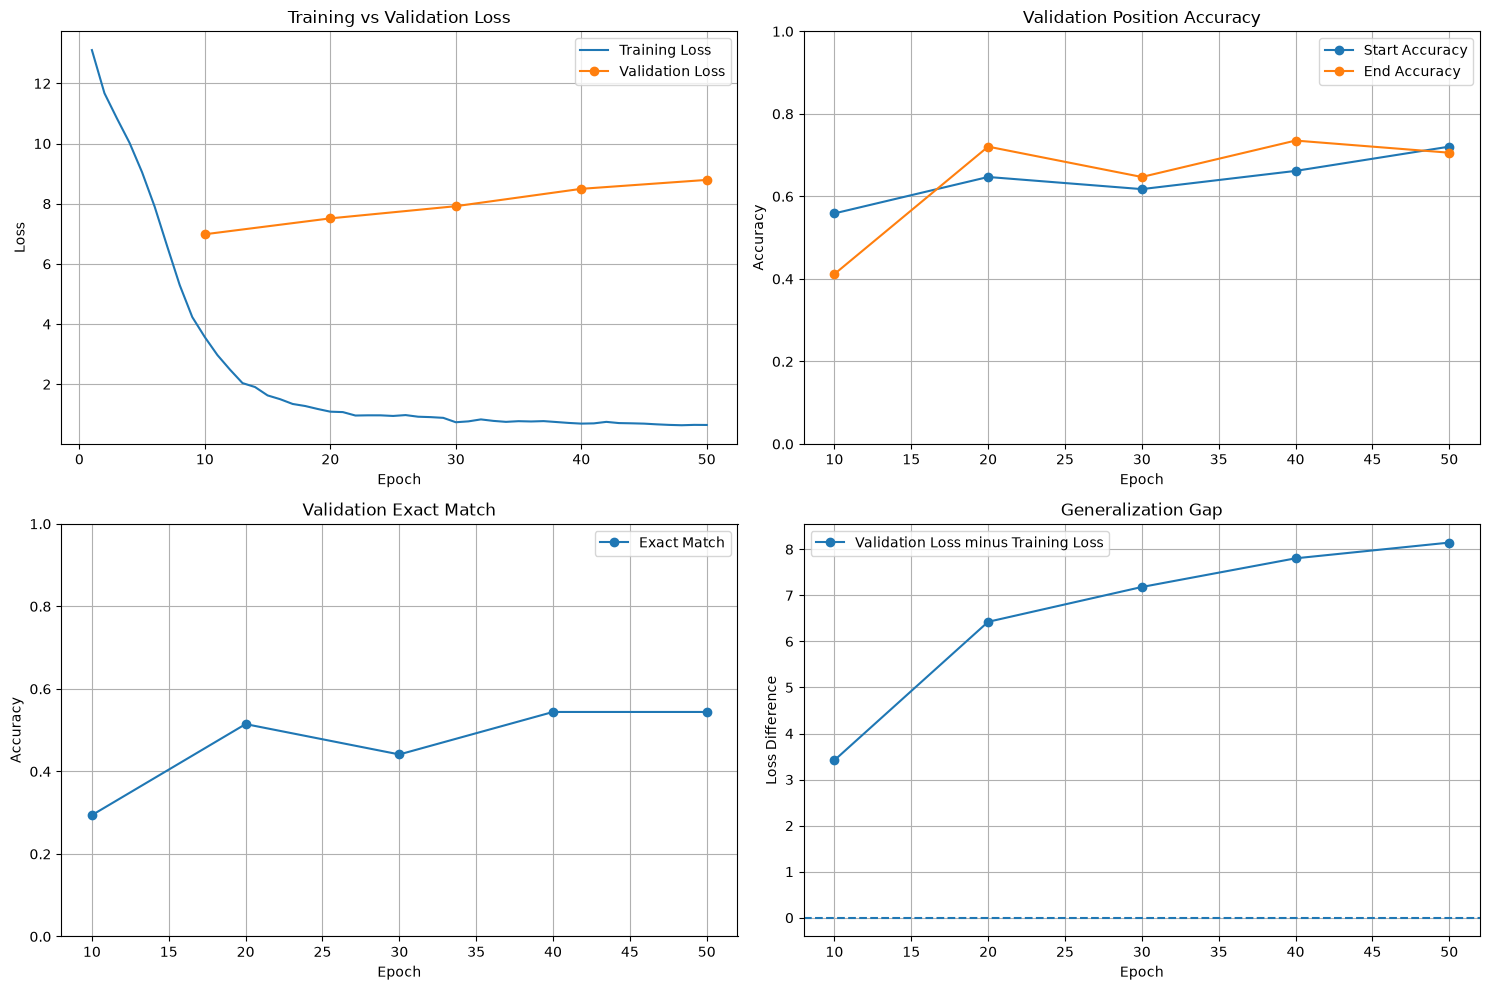

In [23]:

import matplotlib.pyplot as plt
import numpy as np

# Epoch numbers for each metric
train_epochs = np.arange(1, len(history["train_loss"]) + 1)

eval_interval = training_config.eval_interval
val_epochs = np.arange(
    eval_interval,
    eval_interval * len(history["val_loss"]) + 1,
    eval_interval,
)

# Generalization gap at evaluation epochs
train_at_eval = [
    history["train_loss"][epoch - 1]
    for epoch in val_epochs
]

generalization_gap = (
    np.array(history["val_loss"]) -
    np.array(train_at_eval)
)

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# 1. Training vs validation loss
axes[0, 0].plot(
    train_epochs,
    history["train_loss"],
    label="Training Loss",
)

axes[0, 0].plot(
    val_epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss",
)

axes[0, 0].set_title("Training vs Validation Loss")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Loss")
axes[0, 0].legend()
axes[0, 0].grid(True)

# 2. Validation accuracy
axes[0, 1].plot(
    val_epochs,
    history["start_accuracy"],
    marker="o",
    label="Start Accuracy",
)

axes[0, 1].plot(
    val_epochs,
    history["end_accuracy"],
    marker="o",
    label="End Accuracy",
)

axes[0, 1].set_title("Validation Position Accuracy")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend()
axes[0, 1].grid(True)

# 3. Exact match
axes[1, 0].plot(
    val_epochs,
    history["exact_match"],
    marker="o",
    label="Exact Match",
)

axes[1, 0].set_title("Validation Exact Match")
axes[1, 0].set_xlabel("Epoch")
axes[1, 0].set_ylabel("Accuracy")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend()
axes[1, 0].grid(True)

# 4. Generalization gap
axes[1, 1].plot(
    val_epochs,
    generalization_gap,
    marker="o",
    label="Validation Loss minus Training Loss",
)

axes[1, 1].axhline(0, linestyle="--")
axes[1, 1].set_title("Generalization Gap")
axes[1, 1].set_xlabel("Epoch")
axes[1, 1].set_ylabel("Loss Difference")
axes[1, 1].legend()
axes[1, 1].grid(True)

plt.tight_layout()
plt.show()


# Save the model

In [13]:
logger.log(f"Parameters Count: {count_parameters(model):,}")

torch.save(
    model.state_dict(),
    MODEL_DESTINATION,
)
logger.log(f"Saving model to : {MODEL_DESTINATION}")

Saving model to : ../checkpoints/tiny_answering.pt
